----

# Part 3: Numerical Data Analysis

Dr Matteo Degiacomi
Department of Physics, Durham University
<matteo.t.degiacomi@durham.ac.uk>

----

This workshop is centered on using Python packages to analyse numerical data with Numpy and Scipy. You will learn how to:

 *  fit noisy data with linear and non-linear models; 
 *  integrate differential equations;
 *  calculate the derivative of a signal and area under the curve
    
<a class="anchor" id="teabags"></a>


*Acknowledgements*: thanks to Dr Valentina Erastova, University of Edinburgh (www.erastova.xyz), for having shared teaching materials and ideas.

---


## Table of Contents:

### 1.  [fitting data with models](#fitmodels)
  * 1.1. [polynomial fitting](#polyfit)
  * 1.2. [non-linear curve fit](#curvefit)

### 2. [integrating differential equations](#odeint)

### 3. [derivative and integration](#diffandint)
---

## 1. Fitting Models to Data <a class="anchor" id="fitmodels"></a> 

<a class="anchor" id="polyfit"></a> 
Linear least squares is a convex problem. As long as the number of parameters in the model to be fitted is greater than the number of datapoints (i.e. the problem is _overdetermined_) an analytical solution exists. A problem is linear only if model's parameters are related to eachother via sums.

A typical example of linear least squares is that of polynomials fitting. The functions [polyfit](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html) and [polyval](https://numpy.org/doc/stable/reference/generated/numpy.polyval.html), provided within numpy, are dedicated to polynomial fitting.

In [10]:
import numpy as np
import pylab as plt

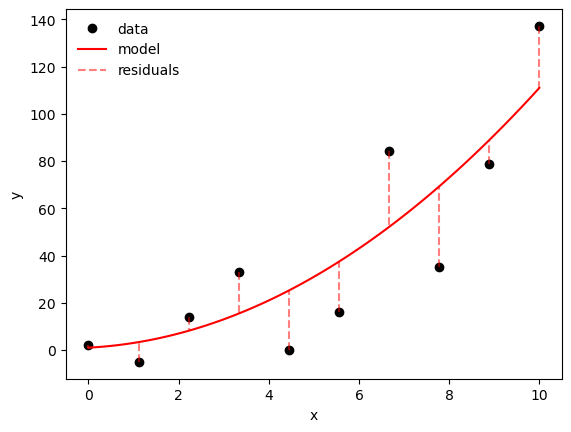

In [11]:
def fct(x, a, b, c):
    return a*x**2 + b*x + c

# generate a noisy signal
coeffs= [1, 1, 1]
x = np.linspace(0, 10, 10)
y_clean = fct(x, *coeffs)
noise = np.random.normal(0, 20, len(x))
y = y_clean + noise

# polynomial fit of noisy signal
poly = np.poly1d(coeffs)
x2 = np.linspace(0, 10, 100)
y2 = poly(x2)

# plot noisy signal and polynomial fit
fig = plt.figure()
plt.plot(x, y, 'ko', label="data")
plt.plot(x2, y2, 'r-', label="model")
plt.xlabel("x")
plt.ylabel("y")

#if you want to display lines representing residuals (toggle replacing "True" with "False")
if True:
    y_predict=poly(x)
    for i, y_tmp in enumerate(y_predict):
        if i == 0:
            plt.plot([x[i], x[i]], [y[i], y_tmp], 'r--', alpha=0.5, label="residuals")
        else:        
            plt.plot([x[i], x[i]], [y[i], y_tmp], 'r--', alpha=0.5)

    
plt.legend(frameon=False, loc="upper left")
plt.savefig("simple_fit.png")

plt.show()

How do we know a fit is good? We can study the **residuals**, i.e. the difference between values in input data, and what the model predicts. Residuals should be Gaussian distributed, and feature no distinguishable trends. Let's see an example with some more complicated data.

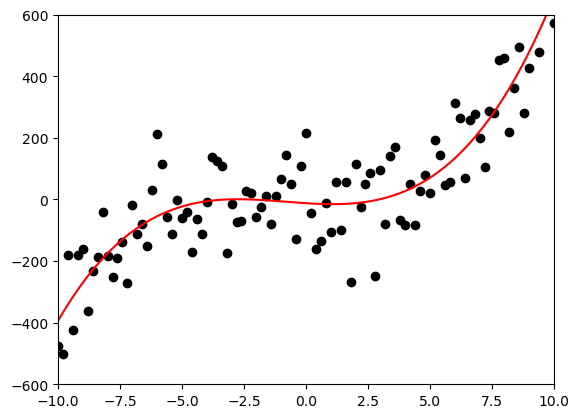

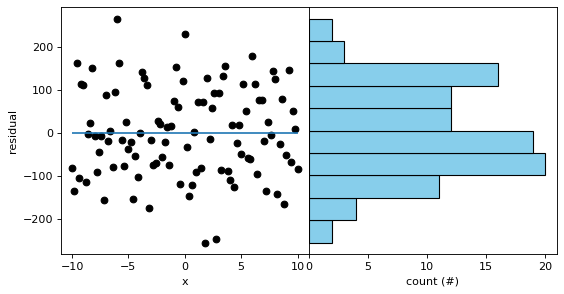

<Figure size 640x480 with 0 Axes>

In [12]:
# polynomial function
def fct(x, a, b, c, d):
    return d*x**3 + c*x**2 - b*x + a

# create some noisy data
x = np.linspace(-10, 10, 101)
y_clean = fct(x, 1, 2, 1, 0.5)
noise = np.random.normal(0, 100, len(x))
y = y_clean + noise

# calculate its third-order polynomial fit
coef, pcov = np.polyfit(x, y, 3, cov=True)
poly = np.poly1d(coef)

# residuals (difference between data and model)
residuals = y-poly(x)

# plot noisy data with fitted model
fig = plt.figure()
x2 = np.linspace(-14, 14, 501)
plt.plot(x, y, 'ko')
plt.plot(x2, poly(x2), 'r-')
plt.xlim([x[0], x[-1]])
plt.ylim([-600, 600])
plt.savefig("data_noise_fit.png")

#plot the model's residuals (left plot) and their histogram (right plot)
fig = plt.figure(dpi=80, figsize=(8, 4))
ax = fig.add_subplot(1, 2, 1)
ax.plot(x, residuals, 'o', color='k') # residuals
ax.hlines(0, -10, 10)
ax.set_ylabel("residual")
ax.set_xlabel("x")

ax = fig.add_subplot(1, 2, 2)
ax.hist(residuals, orientation="horizontal",  color = "skyblue", ec="black") # residuals
ax.set_yticks([])
ax.set_yticklabels([])
fig.subplots_adjust(wspace=0, hspace=0)
ax.set_xlabel("count (#)")

plt.show()
plt.savefig("data_residuals_all.png")

In [13]:
# SOME EXTRA INFORMATION
# you can calculate the properties of your fit
# e.g. analysing its covariance matrix and calculating its coefficient of determination
# To see those analysis, substitute "False" with "True" below"

if False:
    print("polynome coefficients: ", coef)
    pcov[pcov < 0.000000001]= 0
    print("covariance matrix: ", pcov)
    
    # Calculate coefficient of determination (R2)
    ybar = np.sum(y)/len(y)
    ssreg = np.sum((poly(x)- ybar)**2)
    sstot = np.sum((y - ybar)**2)
    det = ssreg / sstot
    print("coeff. of determination: ", det)

    # an alternative way of calculating R2:
    ssres = np.sum((y - poly(x))**2)
    sstot = np.sum((y - ybar)**2)
    det = 1- ssres / sstot
    print("coeff. of determination (method 2): ", det)

What happens if we fit the data with higher order polynomials? We may overfit the data! There are many ways of determing whether a model is overfitting, and thus if we should use a simpler model instead. For instance, for polynomial fits one can observe:
* the sum of squared residuals for incrementally higher order polynomers. A good model is usually located right after an inflection point.
* the highest polynomial parameter. The best model is usually the one with the smallest parameters.

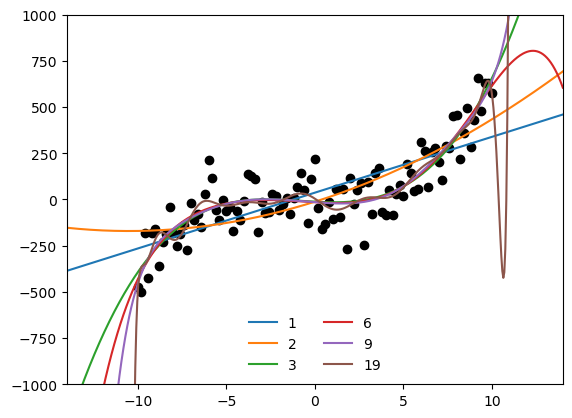

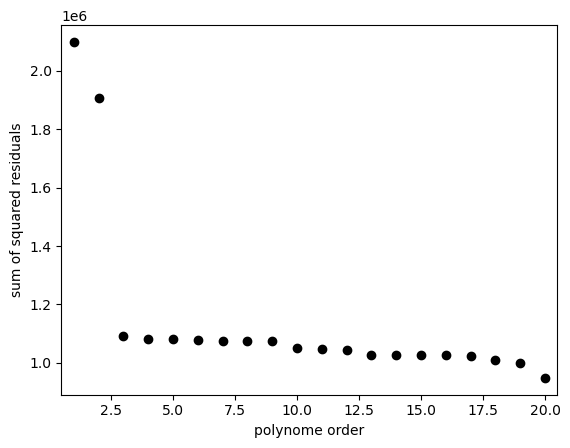

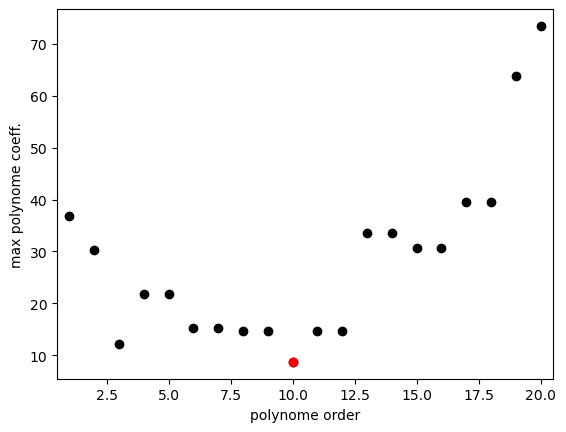

<Figure size 640x480 with 0 Axes>

In [14]:
# fit polynomials of increasingly high order (from 1 to 20)
p = []
order = range(1, 21)
res = []
maxv = []
for i in order:
    vals, resid, rank, sv, rcond = np.polyfit(x, y, i, full=True)
    poly = np.poly1d(vals)
    p.append(poly)
    res.append(resid) 
    maxv.append(np.max(np.abs(vals)))

# plot noisy data with polynomials of increasing order (a subset of all fits previously generated)
fig = plt.figure()
plt.plot(x, y, 'ko')

x2 = np.linspace(-14, 14, 501)
toplot = [0, 1, 2, 5, 8, 18]
for i in toplot:
    plt.plot(x2, p[i](x2), '-', label="%s"%order[i])
    
plt.xlim([x2[0], x2[-1]])
plt.ylim([-1000, 1000])
plt.legend(loc="lower center", ncol=2, frameon=False)
plt.savefig("data_lots_of_poly.png")

#plot sum of squared residuals for every fit
fig = plt.figure()
plt.plot(order, res, 'ko')
plt.xlabel("polynome order")
plt.ylabel("sum of squared residuals")
plt.xlim([0.5, 20.5])
plt.savefig("data_residuals.png")

# plot highest parameter value for every polynomial fit
best = np.argmin(maxv)
fig = plt.figure()
plt.plot(order, maxv, 'ko')
plt.plot([order[best]], [maxv[best]], 'ro')
plt.xlabel("polynome order")
plt.ylabel("max polynome coeff.")
plt.xlim([0.5, 20.5])

plt.show()
plt.savefig("data_coefficients.png")

A sufficiently high polynomial can even fit pure noise!

<div class="alert alert-success">
    <b>TASK 3.1 </b> : What happens if you fit data with a polynome of an order equal to the number of datapoints? Does the result make sense? Plot your fit and make it look nice using matplotlib!
</div>

In [15]:
# this is some random data
N = 20 # number of datapoints
x = np.linspace(-10, 10, N)
y = np.random.normal(0, 10, len(x))

# here, write your code to fit a polynomial of the same order of data (N)
# ...

# here, plot the noisy data and the fitted model
# ...

# ADVANCED: calculate and plot residuals
# ...


<details>
<summary> <mark> SOLUTION:</mark> </summary> 
```python
x = np.linspace(-10, 10, 20)
y = np.random.normal(0, 10, len(x))

vals_20, resid_20, _, _, _ = np.polyfit(x, y, 20, full=True)
poly_20 = np.poly1d(vals_20)

plt.plot(x, y, 'ko')

x2 = np.linspace(-12, 12, 501)
plt.plot(x2, poly_20(x2), 'r-')
    
plt.xlim([x2[0], x2[-1]])
plt.ylim([-30, 30])

plt.show()
plt.savefig("fit_random_noise.png")
```

</details>



<a class="anchor" id="curvefit"></a> 
To fit non-linear models, we cannot use linear least squares.
We will then use a general curve fitting algorithm provided by another Python package: **scipy**.

The [curve_fit](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html) function available in scipy’s optimize module provides methods for fitting models to data (default is Levenberg-Marquardt method).

In the example below, we generate a noisy Gaussian signal, and fit with a Gaussian model. We then observe its residuals to make sure the fit is ok.

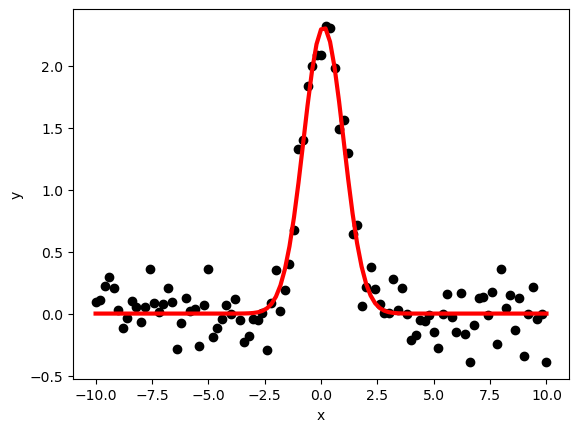

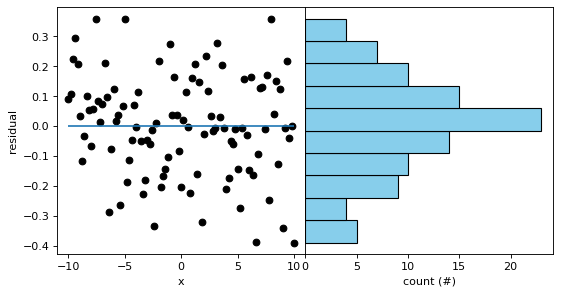

In [16]:
from scipy.optimize import curve_fit

# define a gaussian function
def gaussian(x, ampl, center, width):
    return ampl*np.exp(-(x-center)**2/width)

# create gaussian-distributed noisy data
x = np.linspace(-10, 10, 101)
y = gaussian(x, 2.3, 0.2, 1.5) + np.random.normal(0, 0.2, len(x)) 

# find parameters ideally fitting a gaussian to noisy data
init = [1, 0, 1]
vals, covar = curve_fit(gaussian, x, y, p0=init)

# generate fitted curve profile
yfit = gaussian(x, vals[0], vals[1], vals[2])

# plt noisy data and gaussian fit
plt.figure()
plt.plot(x, y, 'o', color='k') # original data
plt.plot(x, yfit, '-', color = 'r', linewidth=3) # fit
plt.xlabel("x")
plt.ylabel("y")

#plot the model's residuals (left plot) and their histogram (right plot)
residuals = y-yfit

fig = plt.figure(dpi=80, figsize=(8, 4))
ax = fig.add_subplot(1, 2, 1)
ax.plot(x, residuals, 'o', color='k') # residuals
ax.hlines(0, -10, 10)
ax.set_ylabel("residual")
ax.set_xlabel("x")

ax = fig.add_subplot(1, 2, 2)
ax.hist(residuals, orientation="horizontal",  color="skyblue", ec="black") # residuals
ax.set_yticks([])
ax.set_yticklabels([])
fig.subplots_adjust(wspace=0, hspace=0)
ax.set_xlabel("count (#)")

plt.savefig("gaussian_fit.png")
plt.show()

Residuals are are distributed normally around 0, and feature no sytematic trends. This indicates the fit is good.


[back to top](#teabags)

---

## 2. Integrating Differential Equations<a class="anchor" id="odeint"></a> 

Scipy offers the **integrate** module, that allows integrating ordinary differential equations. Here we will use the method [odeint](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.odeint.html).

The prey-predator (a.k.a. Lotka-Volterra) equations are a famous example of coupled differential equations. They describe the trend in the population of two species. Predators diminish when there are not enough preys, prey diminish when there are lots of predators. Let's integrate them!
<img src="images/preypredator.png" width="200">
<a class="anchor" id="coupledodeint"></a>

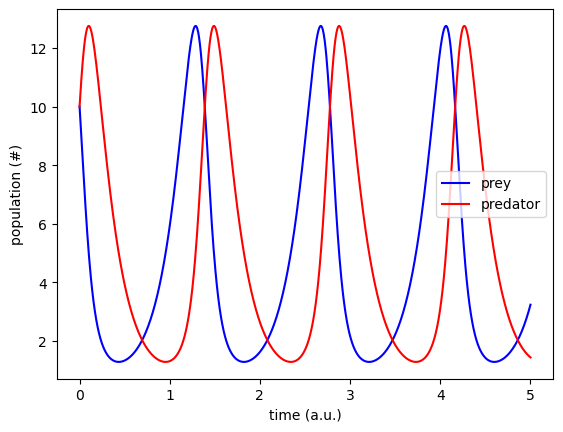

<Figure size 640x480 with 0 Axes>

In [17]:
from scipy.integrate import odeint

def dA_dt(A, t=0): # function to integrate
    prey = (b-p*A[1])*A[0]
    predator = (r*A[0]-d)*A[1]
    return np.array([prey, predator])

t = np.linspace(0, 5, 1000) #time

# define constants and initial parameters
b = 5.0
d = 5.0
p = 1.0
r = 1.0
A_init = np.array([10, 10])

# integrate the differential equation
A_int = odeint(dA_dt, A_init, t)

# plot time versus populations
plt.plot(t, A_int[:, 0], "b", label="prey")
plt.plot(t, A_int[:, 1], "r", label="predator")
plt.legend()

plt.xlabel("time (a.u.)")
plt.ylabel("population (#)")

plt.show()
plt.savefig("prey_predator.png")

An example of irreversible process is that of radioactive decay, where an element converts into another through a series of a series of irreversible steps. In the example below, an element A decays into C via an intermediate B.
<img src="images/radioactive_decay.png" width="200">

<div class="alert alert-success">
    <b>TASK 3.1 </b> : Integrate the system of three coupled differential equations above, describing radioactive decay.    
</div>

In [18]:
# your solution here



<details>
<summary> <mark> SOLUTION:</mark> </summary> 
```python
def dt(vals, t=0): # function to integrate
    dA = -k1*vals[0]
    dB = k1*vals[0] - k2*vals[1]
    dC = k2*vals[1]
    return np.array([dA, dB, dC])

t1 = np.linspace(0, 15, 100) #time
k1 = 1.5
k2 = 0.5
pop_init = np.array([1, 0, 0])
pop_int1 = odeint(dt, pop_init, t1)

# plot the time evolution of the three species
plt.figure(dpi=80, figsize=(12, 4))
plt.subplot(1,1,1)
plt.plot(t1, pop_int1[:, 0], "b", label="A")
plt.plot(t1, pop_int1[:, 1], "r", label="B")
plt.plot(t1, pop_int1[:, 2], "k", label="C")
plt.legend(loc="upper right")

plt.show()

plt.savefig("reactions_all.png")```

</details>




[back to top](#teabags)

---

## 3. Differentiating and Integrating <a class="anchor" id="diffandint"></a> 

Given a signal, common procedures to analyse this data include calculating its derivative and area under the curve. Calculating the derivative is common practive to find edges in images, or identifying maxima/minima. Here are two possible ways to calculate it.
<img src="images/intdiff2.png" width="500">

Calculating the area under the curve (i.e., for infinitely small bins, the integral) can also be calculated in several ways:
<img src="images/intdiff1.png" width="500">

Area under the curve (integration)):
- sum:  0.9999997271639055
- trapezoid: 0.999999686455666


C:\Users\ndc104\AppData\Local\Temp\ipykernel_4792\896819855.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  print("- trapezoid:", np.trapz(y, dx=step))


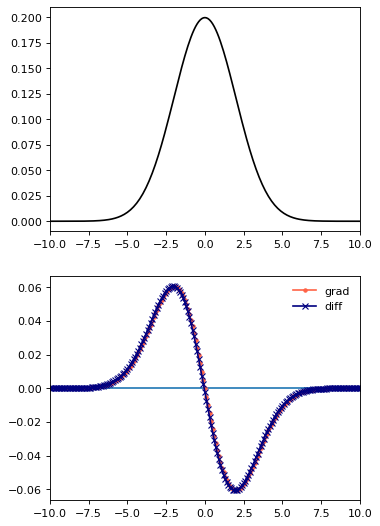

In [19]:
def gaussian(x, mu, sig):
    return 1./(np.sqrt(2.*np.pi)*sig)*np.exp(-np.power((x - mu)/sig, 2.)/2)

step = 0.1
x = np.arange(-10, 11, step)
y = gaussian(x, 0, 2)

# differentiation
y_grad = np.gradient(y, step)
y_diff = np.diff(y)/step

#integration (calculate are under the curve)
print("Area under the curve (integration)):")
print("- sum: ", np.sum(y)*step)
print("- trapezoid:", np.trapz(y, dx=step))

# plot original data
plt.figure(figsize=(5, 8), dpi=80)
plt.subplot(2, 1, 1)
plt.plot(x, y, '-', color='k')
plt.xlim([-10, 10])

# plot differentiation
plt.subplot(2, 1, 2)
plt.hlines(0, -10, 10)
plt.xlim([-10, 10])
plt.plot(x, y_grad, '.-', color='tomato', label="grad")
plt.plot(x[:-1], y_diff, 'x-', color='navy', label="diff")
plt.legend(frameon=False)
plt.show()


Thank you for joining! [back to top](#teabags)